In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Find the repository root.
ROOT = Path.cwd().resolve()
while not (ROOT / "data_labeling").is_dir():
    ROOT = ROOT.parent

OLD_DIR = ROOT / "data_labeling/data_labels/simplified_data_labels"
NEW_DIR = ROOT / "data_labeling/data_labels/sciquality"

print("Project root:", ROOT)

Project root: /Users/piyushluitel/Desktop/PhD/Research/Full-Disk-Attention---Continual-Learning-


In [2]:
# Combine the two previous binary label files.
old_labels = pd.concat(
    [
        pd.read_csv(OLD_DIR / "labels_2010_2018_binary.csv"),
        pd.read_csv(OLD_DIR / "labels_2019_2026_july_binary.csv"),
    ],
    ignore_index=True,
).rename(columns={"goes_class": "old_class"})

new_labels = pd.read_csv(
    NEW_DIR / "labels_sciquality_2010_2026_binary.csv"
).rename(columns={"goes_class": "new_class"})

print("Old labels:", len(old_labels))
print("New labels:", len(new_labels))

Old labels: 128093
New labels: 128117


In [3]:
# Every image path should appear only once.
print("Old duplicate paths:", old_labels["label"].duplicated().sum())
print("New duplicate paths:", new_labels["label"].duplicated().sum())

Old duplicate paths: 0
New duplicate paths: 0


In [4]:
comparison = old_labels.merge(
    new_labels,
    on="label",
    how="outer",
    indicator=True,
)

print(comparison["_merge"].value_counts())

_merge
both          128093
right_only        24
left_only          0
Name: count, dtype: int64


- both       = images found in both versions
- left_only  = images found only in old labels
- right_only = images found only in SciQuality labels

In [5]:
matched = comparison[comparison["_merge"] == "both"].copy()

matched["old_class"] = matched["old_class"].astype(int)
matched["new_class"] = matched["new_class"].astype(int)
matched["changed"] = matched["old_class"] != matched["new_class"]

print("Matched images:", len(matched))
print("Changed labels:", matched["changed"].sum())
print("Agreement (%):", 100 * (~matched["changed"]).mean())

Matched images: 128093
Changed labels: 5386
Agreement (%): 95.79524251910722


In [6]:
transition_table = pd.crosstab(
    matched["old_class"],
    matched["new_class"],
    rownames=["Old label"],
    colnames=["SciQuality label"],
)

transition_table.index = transition_table.index.map({0: "NF", 1: "FL"})
transition_table.columns = transition_table.columns.map({0: "NF", 1: "FL"})

transition_table

SciQuality label,NF,FL
Old label,,
NF,98036,5128
FL,258,24671


In [7]:
prevalence = pd.DataFrame({
    "Old": matched["old_class"].value_counts().sort_index(),
    "SciQuality": matched["new_class"].value_counts().sort_index(),
})

prevalence.index = ["NF", "FL"]
prevalence.loc["FL percentage"] = (
    100 * prevalence.loc["FL"] / prevalence.sum()
)

prevalence

,Old,SciQuality
NF,103164.000000,98294.000000
FL,24929.000000,29799.000000
FL percentage,19.461641,23.263566


In [8]:
# Example path: 2010/12/06/HMI.m2010.12.06_07.00.00.jpg
matched["year"] = matched["label"].str[:4].astype(int)

In [9]:
yearly_summary = matched.groupby("year").agg(
    images=("label", "size"),
    old_fl=("old_class", "sum"),
    new_fl=("new_class", "sum"),
    changed=("changed", "sum"),
)

yearly_summary["agreement_percent"] = (
    100 * (1 - yearly_summary["changed"] / yearly_summary["images"])
)
yearly_summary["old_fl_percent"] = (
    100 * yearly_summary["old_fl"] / yearly_summary["images"]
)
yearly_summary["new_fl_percent"] = (
    100 * yearly_summary["new_fl"] / yearly_summary["images"]
)

yearly_summary.round(2)

,images,old_fl,new_fl,changed,agreement_percent,old_fl_percent,new_fl_percent
year,,,,,,,
2010,562,0,0,0,100.00,0.00,0.00
2011,6528,1235,1595,360,94.49,18.92,24.43
2012,6516,1358,1619,317,95.14,20.84,24.85
2013,7656,1436,1959,527,93.12,18.76,25.59
2014,8405,2702,3522,860,89.77,32.15,41.90
2015,8511,1664,2235,599,92.96,19.55,26.26
2016,8337,250,401,153,98.16,3.00,4.81
2017,8377,330,450,122,98.54,3.94,5.37
2018,8393,0,24,24,99.71,0.00,0.29


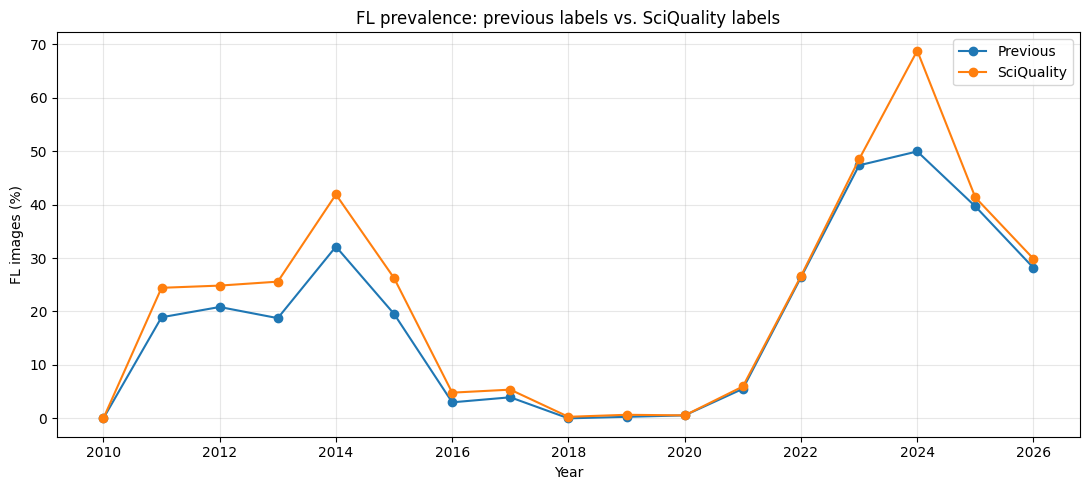

In [10]:
yearly_summary[
    ["old_fl_percent", "new_fl_percent"]
].plot(
    figsize=(11, 5),
    marker="o",
)

plt.title("FL prevalence: previous labels vs. SciQuality labels")
plt.xlabel("Year")
plt.ylabel("FL images (%)")
plt.legend(["Previous", "SciQuality"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()